# ¿El conductor va a traer la tarifa hoy?

**La pregunta que queremos responder:**

> Cada mañana, ¿qué conductores tienen más riesgo de **no** traer la tarifa hoy?

Así el administrador sabe **a quién llamar primero**.

**La idea de la que partimos:** cuando un conductor se empieza a estancar con deudas, deja de pagar la tarifa.

**Los pasos:**

1. Cargar los datos
2. Armar la historia día por día de cada conductor
3. Mirar los datos: ¿es cierto que la deuda influye?
4. Crear las pistas
5. Separar estudio y examen
6. Entrenar: una regla simple y un modelo
7. El examen: ¿quién detecta más días sin pago?
8. La lista de llamadas de hoy

### Palabras clave

| Palabra | Qué significa |
|---|---|
| **Clasificación** | Predecir entre opciones (aquí dos: *trae la tarifa* o *no la trae*), en lugar de un número como en el notebook de ingresos |
| **Probabilidad** | Qué tan seguro está el modelo, de 0 % a 100 %. "85 %" = de cada 100 días así, en unos 85 trae la tarifa |
| **Pista (feature)** | Un dato que le damos al modelo para que adivine. Ej.: "¿cuánto debe?" |
| **Regresión logística** | El modelo de clasificación más simple: combina las pistas y da una probabilidad |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

from datos_pagos import cargar_datos

## 1. Cargar los datos

- `FUENTE = "sintetico"`: 8 conductores inventados durante un año (los genera `datos_pagos.py`).
- `FUENTE = "real"`: lee `tarifas` y `deuda_movements` de PostgreSQL. Úsalo cuando haya al menos 3 meses de datos.
- `SEMILLA`: cambia el número para generar otra flota inventada distinta.

Cómo se comportan los conductores inventados:
- Cada uno tiene un día de pico y placa (ese día no trabaja ni paga).
- A veces les cae una deuda (una multa, un daño, un préstamo).
- Si no traen la tarifa, se les anota como **deuda**.
- Si tienen deuda, algunos días abonan y a veces se les condona una parte.
- **Mientras más deben, y si llevan días sin abonar (estancados), menos probable es que traigan la tarifa.**

In [2]:
FUENTE = "sintetico"
SEMILLA = 42
HOY = pd.Timestamp.today().normalize()
AYER = HOY - pd.Timedelta(days=1)

tarifas, deudas, conductores = cargar_datos(FUENTE, HOY, SEMILLA)
conductores

,conductor,placa,dia_pico_y_placa
0,Andrés,ABC123,1
1,Beatriz,DEF456,2
2,Carlos,GHI789,3
3,Diana,JKL012,4
4,Eduardo,MNO345,5
5,Fabián,PQR678,1
6,Gloria,STU901,2
7,Héctor,VWX234,3


Las tarifas que sí trajeron:

In [3]:
tarifas.head()

,conductor,fecha,pago
0,Andrés,2025-11-26,80000.0
1,Andrés,2025-11-27,80000.0
2,Andrés,2025-11-28,80000.0
3,Andrés,2025-11-29,80000.0
4,Andrés,2025-11-30,80000.0


Los movimientos de deuda, igual que la tabla `deuda_movements` del sistema:
- `debt`: se le suma deuda
- `payment`: abonó
- `forgiveness`: se le condonó una parte

In [4]:
deudas.head(10)

,conductor,fecha,tipo,monto
0,Andrés,2026-07-01,debt,80000.0
1,Andrés,2026-07-02,payment,80000.0
2,Andrés,2026-07-10,debt,300000.0
3,Andrés,2026-07-10,payment,240000.0
4,Andrés,2026-07-14,payment,60000.0
5,Andrés,2026-07-19,debt,80000.0
6,Andrés,2026-07-20,payment,80000.0
7,Andrés,2026-10-08,debt,80000.0
8,Andrés,2026-10-10,debt,80000.0
9,Andrés,2026-10-13,debt,80000.0


## 2. Armar la historia día por día

Juntamos todo en una tabla con **una fila por conductor y por día**:
- `pago`: lo que trajo de tarifa (0 si no trajo nada).
- `cambio_deuda`: cuánto subió (+) o bajó (−) su deuda ese día.
- `abono`: si ese día abonó a la deuda.
- `deuda`: cuánto debía al final del día.

In [5]:
def armar_dias(tarifas, deudas, conductores, hasta):
    inicio = min(tarifas["fecha"].min(), deudas["fecha"].min())
    todos_los_dias = pd.MultiIndex.from_product(
        [conductores["conductor"], pd.date_range(inicio, hasta)], names=["conductor", "fecha"]
    ).to_frame(index=False)

    dias = todos_los_dias.merge(conductores, on="conductor")
    dias = dias.merge(tarifas, on=["conductor", "fecha"], how="left")
    dias["pago"] = dias["pago"].fillna(0)

    signo = deudas["tipo"].map({"debt": 1, "payment": -1, "forgiveness": -1})
    movimientos = deudas.assign(cambio_deuda=deudas["monto"] * signo, abono=deudas["tipo"] == "payment")
    por_dia = movimientos.groupby(["conductor", "fecha"], as_index=False)[["cambio_deuda", "abono"]].sum()
    dias = dias.merge(por_dia, on=["conductor", "fecha"], how="left").fillna({"cambio_deuda": 0, "abono": 0})

    dias = dias.sort_values(["conductor", "fecha"]).reset_index(drop=True)
    dias["deuda"] = dias.groupby("conductor")["cambio_deuda"].cumsum()
    return dias


dias = armar_dias(tarifas, deudas, conductores, AYER)

un_conductor = dias.groupby("conductor")["deuda"].max().idxmax()
dia_de_mas_deuda = dias.loc[dias[dias["conductor"] == un_conductor]["deuda"].idxmax(), "fecha"]
ventana = (dias["conductor"] == un_conductor) & dias["fecha"].between(dia_de_mas_deuda - pd.Timedelta(days=20), dia_de_mas_deuda)

print(f"Ejemplo: {un_conductor}, el conductor que llegó a deber más. Los 20 días antes de su peor momento:")
dias[ventana][["conductor", "fecha", "pago", "cambio_deuda", "abono", "deuda"]]

Ejemplo: Eduardo, el conductor que llegó a deber más. Los 20 días antes de su peor momento:


,conductor,fecha,pago,cambio_deuda,abono,deuda
1761,Eduardo,2026-09-23,0.0,70000.0,0.0,680000.0
1762,Eduardo,2026-09-24,70000.0,0.0,0.0,680000.0
1763,Eduardo,2026-09-25,0.0,0.0,0.0,680000.0
1764,Eduardo,2026-09-26,70000.0,0.0,0.0,680000.0
1765,Eduardo,2026-09-27,70000.0,0.0,0.0,680000.0
1766,Eduardo,2026-09-28,0.0,70000.0,0.0,750000.0
1767,Eduardo,2026-09-29,70000.0,0.0,0.0,750000.0
1768,Eduardo,2026-09-30,70000.0,0.0,0.0,750000.0
1769,Eduardo,2026-10-01,70000.0,0.0,0.0,750000.0
1770,Eduardo,2026-10-02,0.0,0.0,0.0,750000.0


## 3. Mirar los datos: ¿la deuda influye?

Antes de usar un modelo, comprobamos la idea de la que partimos. Agrupamos los días de trabajo según **cuántas tarifas debía el conductor ese día** y miramos en qué porcentaje trajo la tarifa.

Medimos la deuda **en tarifas** (deuda ÷ tarifa del conductor) para poder comparar conductores con tarifas distintas: "debe 3 tarifas" significa lo mismo para todos.

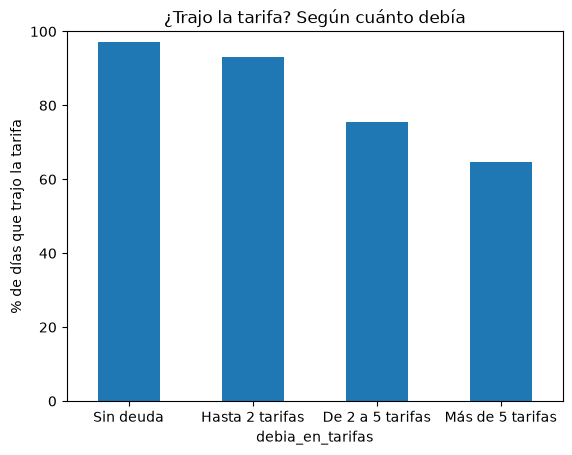

In [6]:
tarifa_de_cada_uno = tarifas.groupby("conductor")["pago"].median()

trabajo = dias[dias["fecha"].dt.day_of_week + 1 != dias["dia_pico_y_placa"]].copy()
trabajo["trajo_tarifa"] = (trabajo["pago"] > 0).astype(int)
deuda_ayer = trabajo.groupby("conductor")["deuda"].shift(1).fillna(0)
trabajo["debia_en_tarifas"] = deuda_ayer / trabajo["conductor"].map(tarifa_de_cada_uno)

grupos = pd.cut(
    trabajo["debia_en_tarifas"],
    bins=[-np.inf, 0, 2, 5, np.inf],
    labels=["Sin deuda", "Hasta 2 tarifas", "De 2 a 5 tarifas", "Más de 5 tarifas"],
)
porcentaje_que_paga = trabajo.groupby(grupos, observed=True)["trajo_tarifa"].mean() * 100

porcentaje_que_paga.plot.bar(rot=0, title="¿Trajo la tarifa? Según cuánto debía")
plt.ylabel("% de días que trajo la tarifa")
plt.ylim(0, 100)
plt.show()

**Sí:** mientras más debe, menos trae la tarifa. La idea se confirma, así que tiene sentido usar la deuda como pista.

¿Y cada conductor?

In [7]:
resumen = trabajo.groupby("conductor").agg(
    porcentaje_dias_que_trajo_tarifa=("trajo_tarifa", lambda trajo: trajo.mean() * 100),
    deuda_maxima=("deuda", "max"),
)
resumen.round(0).sort_values("porcentaje_dias_que_trajo_tarifa")

,porcentaje_dias_que_trajo_tarifa,deuda_maxima
conductor,,
Eduardo,85.0,1380000.0
Beatriz,93.0,600000.0
Héctor,95.0,430000.0
Carlos,96.0,150000.0
Fabián,97.0,140000.0
Diana,97.0,375000.0
Gloria,97.0,170000.0
Andrés,98.0,240000.0


## 4. Crear las pistas

Cada mañana queremos predecir **hoy** usando lo que sabemos **hasta ayer**. A diferencia del notebook de ingresos (que pronosticaba 7 días), aquí sí podemos usar lo que pasó ayer.

Solo usamos los días en que el conductor trabaja: el día de pico y placa no se espera tarifa.

El modelo usa solo **2 pistas**, las de tu experiencia: **cuánto debe** y **si está estancado**.

| Pista | Qué dice |
|---|---|
| `deuda_en_tarifas` | Cuánto debía ayer, medido en tarifas |
| `dias_sin_abonar` | Si tiene deuda, cuántos días lleva sin abonar (máximo 60). Es lo que llamas **estancarse**. `0` si no debe nada |

Y calculamos una columna más, que **no** es pista del modelo, sino la base de la **regla simple** del paso 6:

| Columna | Qué dice |
|---|---|
| `pago_4_semanas` | Qué parte de los últimos 24 días de trabajo (unas 4 semanas) trajo la tarifa. `0.9` = 90 % |

> **¿Por qué solo 2 pistas?** Probamos también con `pago_4_semanas` y "días seguidos sin pagar", y el modelo detectó lo mismo. Como cada tarifa no pagada se suma a la deuda, esas pistas **repetían la misma información** y solo confundían al modelo. Más pistas no siempre es mejor (lo puedes comprobar en el ejercicio 3).

La función `contar_dias_sin_abonar` recorre los días en orden, como si fueras pasando las hojas de un cuaderno, y va contando.

In [8]:
def contar_dias_sin_abonar(abonos):
    contador, resultado = 60, []
    for abono in abonos:
        resultado.append(contador)
        contador = 1 if abono else min(contador + 1, 60)
    return pd.Series(resultado, index=abonos.index)


def agregar_pistas(dias, tarifa_de_cada_uno):
    dias = dias.copy()
    dias["deuda_ayer"] = dias.groupby("conductor")["deuda"].shift(1).fillna(0)
    dias["deuda_en_tarifas"] = (dias["deuda_ayer"] / dias["conductor"].map(tarifa_de_cada_uno)).clip(lower=0).round(1)
    dias["dias_sin_abonar"] = dias.groupby("conductor")["abono"].transform(contar_dias_sin_abonar)
    dias.loc[dias["deuda_ayer"] <= 0, "dias_sin_abonar"] = 0

    trabajo = dias[dias["fecha"].dt.day_of_week + 1 != dias["dia_pico_y_placa"]].copy()
    trabajo["trajo_tarifa"] = (trabajo["pago"] > 0).astype(int)
    trabajo["pago_4_semanas"] = trabajo.groupby("conductor")["trajo_tarifa"].transform(
        lambda trajo: trajo.shift(1).rolling(24, min_periods=6).mean()
    )
    return trabajo


PISTAS = ["deuda_en_tarifas", "dias_sin_abonar"]

datos = agregar_pistas(dias, tarifa_de_cada_uno).dropna(subset=[*PISTAS, "pago_4_semanas"])
print(f"Días de trabajo para estudiar y examinar: {len(datos):,}")

ventana = (datos["conductor"] == un_conductor) & datos["fecha"].between(
    dia_de_mas_deuda - pd.Timedelta(days=20), dia_de_mas_deuda
)
datos[ventana][["conductor", "fecha", "trajo_tarifa", *PISTAS, "pago_4_semanas"]]

Días de trabajo para estudiar y examinar: 2,454


,conductor,fecha,trajo_tarifa,deuda_en_tarifas,dias_sin_abonar,pago_4_semanas
1761,Eduardo,2026-09-23,0,8.7,8,0.583333
1762,Eduardo,2026-09-24,1,9.7,9,0.541667
1764,Eduardo,2026-09-26,1,9.7,11,0.541667
1765,Eduardo,2026-09-27,1,9.7,12,0.541667
1766,Eduardo,2026-09-28,0,9.7,13,0.541667
1767,Eduardo,2026-09-29,1,10.7,14,0.541667
1768,Eduardo,2026-09-30,1,10.7,15,0.541667
1769,Eduardo,2026-10-01,1,10.7,16,0.583333
1771,Eduardo,2026-10-03,0,10.7,18,0.625000
1772,Eduardo,2026-10-04,0,11.7,19,0.583333


Fíjate en la tabla: cuando `deuda_en_tarifas` y `dias_sin_abonar` suben, empiezan a aparecer ceros en `trajo_tarifa`.

## 5. Separar estudio y examen

Igual que antes: el modelo estudia con el pasado y presenta el examen con las **últimas 8 semanas**, que nunca vio. Usamos 8 semanas (y no 4) porque los días sin pago son pocos y queremos suficientes para evaluar.

In [9]:
inicio_examen = datos["fecha"].max() - pd.Timedelta(days=55)
estudio = datos[datos["fecha"] < inicio_examen]
examen = datos[datos["fecha"] >= inicio_examen].copy()

print(f"Estudio: {estudio['fecha'].min():%d/%m/%Y} a {estudio['fecha'].max():%d/%m/%Y} → {len(estudio):,} días de trabajo")
print(f"Examen:  {examen['fecha'].min():%d/%m/%Y} a {examen['fecha'].max():%d/%m/%Y} → {len(examen):,} días de trabajo")
print(f"Días sin tarifa en el examen: {(examen['trajo_tarifa'] == 0).sum()}")

Estudio: 03/12/2025 a 30/09/2026 → 2,070 días de trabajo
Examen:  01/10/2026 a 25/11/2026 → 384 días de trabajo
Días sin tarifa en el examen: 35


## 6. Entrenar: una regla simple y un modelo

**La regla simple** (sin machine learning):

> "La probabilidad de que traiga la tarifa hoy es el porcentaje de días que la trajo en las últimas 4 semanas."

Es literalmente la pista `pago_4_semanas`. No necesita entrenarse.

**El modelo: regresión logística.** Le da un **peso** a cada pista, las combina y convierte el resultado en una probabilidad entre 0 % y 100 %. Los pesos los aprende solo, mirando los días de estudio.

In [10]:
modelo = LogisticRegression(max_iter=1000)
modelo.fit(estudio[PISTAS], estudio["trajo_tarifa"])

pd.Series(modelo.coef_[0], index=PISTAS).round(2).to_frame("peso")

,peso
deuda_en_tarifas,-0.39
dias_sin_abonar,-0.02


**Cómo leer los pesos:**
- **Negativo** → cuando esa pista sube, **baja** la probabilidad de que traiga la tarifa.
- **Positivo** → cuando sube, la probabilidad **sube**.
- Mientras más lejos de 0, más fuerte empuja. El peso es **por cada unidad** de la pista: por cada tarifa de deuda, por cada día sin abonar, etc.

Los dos pesos deberían salir **negativos**: más deuda y más días sin abonar → menos probabilidad de traer la tarifa. El modelo aprendió solo, mirando los datos, lo que tú ya sabías por experiencia.

## 7. El examen

### Primero, una trampa

La forma más obvia de medir sería "¿en qué porcentaje de días acertó?". Pero mira lo que pasa con una regla tonta que dice que **todos pagan siempre**:

In [11]:
dias_sin_pago = (examen["trajo_tarifa"] == 0).sum()
aciertos_siempre_paga = (examen["trajo_tarifa"] == 1).mean()

print(f"'Todos pagan siempre' acierta el {aciertos_siempre_paga:.0%} de los días...")
print(f"...pero de los {dias_sin_pago} días sin tarifa no detecta NINGUNO.")

'Todos pagan siempre' acierta el 91% de los días...
...pero de los 35 días sin tarifa no detecta NINGUNO.


Como casi siempre pagan, decir "sí paga" casi siempre acierta, pero no sirve para nada. Por eso hay que medir **lo que le importa al administrador**:

### La lista de llamadas

> Cada mañana llamas a los **2 conductores con menos probabilidad** de traer la tarifa. Al final del examen, ¿cuántos de los días sin tarifa estaban en tu lista?

Comparamos tres formas de armar la lista: **al azar**, con la **regla simple** y con el **modelo**.

In [12]:
LLAMADAS_POR_DIA = 2

examen["probabilidad_azar"] = np.random.default_rng(SEMILLA).random(len(examen))
examen["probabilidad_regla"] = examen["pago_4_semanas"]
examen["probabilidad_modelo"] = modelo.predict_proba(examen[PISTAS])[:, 1]


def dias_sin_pago_detectados(examen, columna):
    lista_de_llamadas = examen.sort_values(columna).groupby("fecha").head(LLAMADAS_POR_DIA)
    return (lista_de_llamadas["trajo_tarifa"] == 0).sum()


resultado = pd.DataFrame(
    {
        "detectados": {
            "Al azar": dias_sin_pago_detectados(examen, "probabilidad_azar"),
            "Regla simple": dias_sin_pago_detectados(examen, "probabilidad_regla"),
            "Modelo": dias_sin_pago_detectados(examen, "probabilidad_modelo"),
        }
    }
)
resultado["porcentaje"] = (resultado["detectados"] / dias_sin_pago * 100).round(0)
resultado

,detectados,porcentaje
Al azar,12,34.0
Regla simple,21,60.0
Modelo,24,69.0


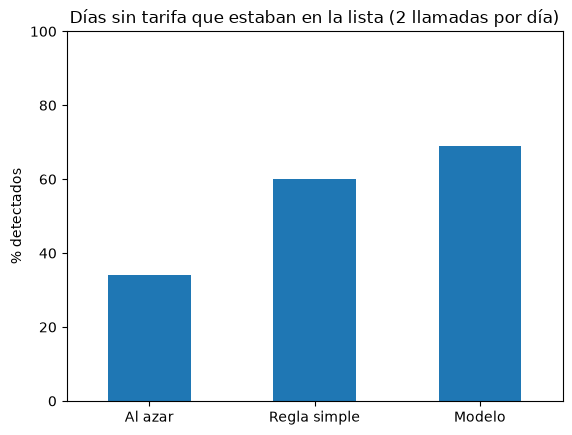

In [13]:
resultado["porcentaje"].plot.bar(rot=0, title=f"Días sin tarifa que estaban en la lista ({LLAMADAS_POR_DIA} llamadas por día)")
plt.ylabel("% detectados")
plt.ylim(0, 100)
plt.show()

**Cómo leer el resultado:**
- **Al azar** es lo que pasaría sin ningún análisis.
- Si la **regla simple** ya está muy por encima del azar, el historial de pagos sirve por sí solo.
- El **modelo** solo vale la pena si le gana claramente a la regla simple. Aquí le puede ganar porque además mira la **deuda** y si el conductor está **estancado**, y la regla no.

> ⚠️ Los datos inventados se generaron con la regla "más deuda → paga menos", así que el modelo la encuentra. Con datos reales hay que repetir este examen para saber si de verdad le gana a la regla simple.

## 8. La lista de llamadas de hoy

1. Entrenamos el modelo con **todos** los días (estudio + examen).
2. Calculamos las pistas de **hoy** con lo que sabemos hasta ayer.
3. Ordenamos de menor a mayor probabilidad: los primeros son a quienes hay que llamar.

In [14]:
modelo_final = LogisticRegression(max_iter=1000)
modelo_final.fit(datos[PISTAS], datos["trajo_tarifa"])

dias_hasta_hoy = armar_dias(tarifas, deudas, conductores, HOY)
hoy = agregar_pistas(dias_hasta_hoy, tarifa_de_cada_uno)
hoy = hoy[hoy["fecha"] == HOY].dropna(subset=PISTAS).copy()
hoy["probabilidad_de_traerla"] = (modelo_final.predict_proba(hoy[PISTAS])[:, 1] * 100).round(0)

descansan_hoy = conductores.loc[conductores["dia_pico_y_placa"] == HOY.day_of_week + 1, "conductor"].tolist()
print(f"Hoy {HOY:%d/%m/%Y} tienen pico y placa: {descansan_hoy or 'nadie'}. No trabajan, así que no se espera su tarifa y no aparecen en la lista.")

hoy.sort_values("probabilidad_de_traerla")[["conductor", "placa", "probabilidad_de_traerla", *PISTAS, "pago_4_semanas"]]

Hoy 26/11/2026 tienen pico y placa: ['Diana']. No trabajan, así que no se espera su tarifa y no aparecen en la lista.


,conductor,placa,probabilidad_de_traerla,deuda_en_tarifas,dias_sin_abonar,pago_4_semanas
2195,Fabián,PQR678,92.0,2.0,22,0.875000
2927,Héctor,VWX234,96.0,0.6,2,0.875000
365,Andrés,ABC123,97.0,0.0,0,1.000000
731,Beatriz,DEF456,97.0,0.0,0,1.000000
1829,Eduardo,MNO345,97.0,0.0,0,0.916667
1097,Carlos,GHI789,97.0,0.0,0,0.958333
2561,Gloria,STU901,97.0,0.0,0,0.958333


Las pistas al lado de cada conductor explican **por qué** está arriba en la lista: por ejemplo, "debe 4 tarifas y lleva 15 días sin abonar". Eso sirve para la conversación con el conductor. Si todos salen con probabilidad alta, hoy no hay nadie en riesgo.

## Ejercicios para practicar

Cambia una cosa a la vez, vuelve a ejecutar todo (*Run All*) y mira la tabla del paso 7:

1. **Más o menos llamadas:** cambia `LLAMADAS_POR_DIA` a `1` o `3`. ¿Cómo cambian los detectados?
2. **Una sola pista:** deja `PISTAS = ["deuda_en_tarifas"]`. ¿Cuánto logra solo con la deuda?
3. **Más pistas:** agrega `"pago_4_semanas"` a `PISTAS`. ¿Detecta más días sin pago? ¿Qué pasa con los pesos? ¿Tienen sentido?
4. **Otra flota:** cambia `SEMILLA` a `1`, `2`, `3`… ¿El modelo siempre le gana a la regla? (Spoiler: no siempre; por eso se prueba varias veces.)
5. **Si la deuda no importara:** en `datos_pagos.py`, cambia `0.04` por `0` y `0.30` por `0` en la línea de `probabilidad`. ¿Qué pasa con los pesos y con el examen? Un modelo solo encuentra patrones que **existen** en los datos.
6. **Otro modelo:** importa `DecisionTreeClassifier` de `sklearn.tree`, úsalo con `max_depth=3` en lugar de `LogisticRegression` y muestra sus reglas con `export_text`, como en el notebook de ingresos.
7. **Datos reales:** cuando haya historia, cambia `FUENTE = "real"`.